# Latent Diffusion for Unconditional Fluorescence Microscopy Image Generation

## Project Overview

This notebook implements an unconditional **Latent Diffusion Model (LDM)** for generating synthetic microscopy images using the BBBC038 dataset. The experiment investigates the feasibility of training a diffusion-based generative model under limited-data conditions and examines how restricting the training data to a more visually homogeneous subset affects image generation.

The model performs diffusion in a compressed latent space rather than directly in pixel space. A pretrained Variational Autoencoder (VAE) encodes microscopy images into compact latent representations, a U-Net learns to predict the noise added to these representations, and a diffusion sampling process generates new latent representations that are decoded back into image space.

## Dataset and Subset Selection

The experiment uses the **BBBC038 dataset**, which contains microscopy images and corresponding nuclear segmentation annotations.

An image-level dataset audit was performed across all 670 images to examine dataset characteristics and identify broad visual appearance patterns. K-means clustering was used as an exploratory method to group images according to their visual characteristics.

The largest appearance cluster (Cluster 0) was selected to investigate whether training on a more visually consistent subset could make unconditional generation more manageable in a low-data setting.

The dataset was divided at the image level using a deterministic random seed of 42:
- **Training pool:** 536 images
- **Validation set:** 67 images
- **Held-out test set:** 67 images

From the training pool, 100 images belonging to Cluster 0 were selected for model training. The corresponding same-cluster validation and test subsets contain 32 and 37 images, respectively.

The appearance clusters are exploratory groupings and should not be interpreted as verified biological categories or microscopy modalities. Furthermore, the selected cluster was not explicitly restricted to fluorescence-only images; results should therefore be interpreted in the context of the audited BBBC038 image collection.

## Image Preprocessing

Images are resized to a resolution of **128 × 128 pixels** while preserving their original aspect ratios. Padding is used to obtain a consistent input size without introducing the geometric distortions associated with direct square resizing.

Image padding uses the median corner intensity, while segmentation masks are padded with zeros. This preprocessing provides a uniform input representation while retaining the original image geometry as closely as possible.

## Model Architecture and Training

The generative pipeline consists of two main components:

1. **Pretrained VAE:** The `stabilityai/sd-vae-ft-mse` VAE is used as a frozen encoder-decoder. It maps each 128 × 128 image into a compact latent representation with four channels and a spatial resolution of 16 × 16. The posterior mean is used to obtain the latent representation, which is scaled by 0.18215.
2. **Latent U-Net:** A compact U-Net, containing approximately 2.00 million trainable parameters, learns to predict the noise added to the latent representations at different diffusion timesteps.

The latent representations are standardised using per-channel statistics calculated exclusively from the training data. A 200-step cosine noise schedule is used for the forward diffusion process.

Training uses the AdamW optimiser with a learning rate of \(1 \times 10^{-4}\), weight decay of \(1 \times 10^{-4}\), automatic mixed precision, gradient clipping, and an Exponential Moving Average (EMA) of model parameters with a decay rate of 0.995. The training budget is capped at 5,000 optimisation steps.

## Validation and Sampling

Validation uses fixed noise and fixed diffusion timesteps so that validation losses can be compared consistently across training checkpoints. The EMA model is evaluated during training, and the checkpoint with the lowest validation noise-prediction MSE is retained for generation.

Generated images are produced using a 50-step deterministic DDIM-style sampling procedure. The resulting latent samples are decoded through the pretrained VAE to obtain images in pixel space.

The notebook also evaluates VAE reconstruction quality before full model training, providing a check of how well the pretrained encoder-decoder preserves the input microscopy images.

## Evaluation

Generation quality is examined through visual inspection and quantitative comparisons of nuclear morphology.

For the quantitative diagnostic, nuclear regions are identified in generated images using Otsu thresholding followed by connected-component analysis. Three features are compared against the corresponding real-image annotations:

- Nuclear area
- Number of detected nuclei
- Nuclear area fraction

The distributions are compared using the Hellinger distance. These measurements provide a diagnostic indication of morphological similarity rather than a definitive measure of biological realism. In particular, generated-image masks are obtained automatically, whereas the real dataset provides annotated nuclear masks; this difference should be considered when interpreting the results.

## Experimental Scope

This LDM experiment is a separate **100-image feasibility study** within the broader comparison of generative approaches for low-data microscopy synthesis. It is not a directly controlled, like-for-like comparison with the StyleGAN2-ADA and pixel-space DDPM experiments, which use fluorescence-only image patches and nested training subsets.

The purpose of this experiment is to investigate the behaviour of latent diffusion under a restricted training-data regime, document its training and sampling performance, and identify the challenges involved in generating structurally meaningful microscopy images from limited data.

## 0. Runtime and reproducibility
Run cells top-to-bottom in a fresh Colab GPU runtime. Do not run multiple training cells concurrently.

In [1]:
import os, sys, json, math, random, time, zipfile, shutil
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
from tqdm.auto import tqdm
import cv2

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
os.environ["PYTHONHASHSEED"] = str(SEED)

import torch
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
assert torch.cuda.is_available(), "Enable Runtime > Change runtime type > GPU."
DEVICE = "cuda"
print("Python:", sys.version)
print("PyTorch:", torch.__version__)
print("GPU:", torch.cuda.get_device_name(0))
print("VRAM (GB):", round(torch.cuda.get_device_properties(0).total_memory/1024**3, 2))
!nvidia-smi


Python: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
PyTorch: 2.14.1+cu130
GPU: Tesla T4
VRAM (GB): 14.56
Sat Nov 21 17:10:02 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   47C    P8             14W /   70W |       3MiB /  15360MiB |      0%      Default |
|                           

## 1. Install dependencies

The VAE class used below is provided by Diffusers.

In [2]:
%pip -q install diffusers==0.30.3 accelerate safetensors huggingface_hub opencv-python-headless pandas matplotlib tqdm scikit-learn


## 2. Mount Drive and use the complete extracted dataset

In [3]:
from google.colab import drive
drive.mount('/content/drive')

ROOT = Path('/content/drive/MyDrive/BBBC038_LDM')
EXTRACT_DIR = ROOT / 'data_extracted_full' / 'stage1_train'
AUDIT_DIR = ROOT / 'dataset_audit'
CLUSTER_CSV = AUDIT_DIR / 'appearance_clusters.csv'

assert EXTRACT_DIR.exists(), f"Missing complete extracted dataset: {EXTRACT_DIR}"
assert CLUSTER_CSV.exists(), f"Missing {CLUSTER_CSV}. Run the complete Dataset Audit notebook first."

RUN_TAG = 'final_homogeneous_cluster100'
OUTPUT_ROOT = ROOT / 'ldm_outputs' / RUN_TAG
CACHE_DIR = OUTPUT_ROOT / 'latent_cache'
CHECKPOINT_DIR = OUTPUT_ROOT / 'checkpoints'
SAMPLE_DIR = OUTPUT_ROOT / 'generated_samples'
for p in [OUTPUT_ROOT, CACHE_DIR, CHECKPOINT_DIR, SAMPLE_DIR]:
    p.mkdir(parents=True, exist_ok=True)

print("Dataset:", EXTRACT_DIR)
print("Audit cluster labels:", CLUSTER_CSV)
print("THIS RUN OUTPUTS:", OUTPUT_ROOT)
print("Checkpoints:", CHECKPOINT_DIR)
print("Generated samples:", SAMPLE_DIR)


Mounted at /content/drive
Dataset: /content/drive/MyDrive/BBBC038_LDM/data_extracted_full/stage1_train
Audit cluster labels: /content/drive/MyDrive/BBBC038_LDM/dataset_audit/appearance_clusters.csv
THIS RUN OUTPUTS: /content/drive/MyDrive/BBBC038_LDM/ldm_outputs/final_homogeneous_cluster100
Checkpoints: /content/drive/MyDrive/BBBC038_LDM/ldm_outputs/final_homogeneous_cluster100/checkpoints
Generated samples: /content/drive/MyDrive/BBBC038_LDM/ldm_outputs/final_homogeneous_cluster100/generated_samples


## 3. Discover all 670 images and their masks

In [4]:
IMG_EXTS = {'.png','.jpg','.jpeg','.tif','.tiff'}
records=[]
for p in sorted(EXTRACT_DIR.rglob('*')):
    if p.is_file() and p.suffix.lower() in IMG_EXTS and p.parent.name.lower()=='images':
        image_id=p.parent.parent.name
        mask_dir=p.parent.parent/'masks'
        records.append({'image_id':image_id,'image_path':str(p),'mask_dir':str(mask_dir)})

# One image per ID; deterministic order.
by_id={r['image_id']:r for r in records}
records=[by_id[k] for k in sorted(by_id)]
assert len(records)==670, f"Expected 670 images; found {len(records)}"
assert all(Path(r['mask_dir']).is_dir() for r in records), "At least one mask directory is missing."
print("Images:",len(records),"| image IDs:",len(set(r['image_id'] for r in records)))


Images: 670 | image IDs: 670


## 4. Reproducible image-level split and homogeneous subset selection
We create a new deterministic 80/10/10 split using sorted image IDs. The held-out test set remains untouched during training. The largest K-means appearance cluster is selected from the audit CSV; 100 members are sampled from that cluster's training-pool members.

In [5]:
from sklearn.model_selection import train_test_split

ids=np.array([r['image_id'] for r in records])
train_pool_ids, hold_ids=train_test_split(ids,test_size=0.20,random_state=SEED)
val_ids, test_ids=train_test_split(hold_ids,test_size=0.50,random_state=SEED)
lookup={r['image_id']:r for r in records}
train_pool=[lookup[i] for i in train_pool_ids]
val_all=[lookup[i] for i in val_ids]
test_all=[lookup[i] for i in test_ids]

cluster_df=pd.read_csv(CLUSTER_CSV)
assert {'image_id','cluster'}.issubset(cluster_df.columns)
cluster_map=dict(zip(cluster_df.image_id.astype(str),cluster_df.cluster.astype(int)))
assert set(ids).issubset(set(cluster_map)), "Audit cluster CSV does not contain all image IDs."

largest_cluster=int(cluster_df.cluster.value_counts().idxmax())
cluster_train=[r for r in train_pool if cluster_map[r['image_id']]==largest_cluster]
assert len(cluster_train)>=100, f"Largest cluster has only {len(cluster_train)} training-pool images."

rng=np.random.default_rng(SEED+910)
chosen=rng.choice(len(cluster_train),size=100,replace=False)
active_records=[cluster_train[i] for i in sorted(chosen)]
active_ids=[r['image_id'] for r in active_records]

# Validation loss is measured on held-out images from the same appearance cluster.
val_records=[r for r in val_all if cluster_map[r['image_id']]==largest_cluster]
# For morphology comparison, use held-out test images from that cluster as well.
test_records=[r for r in test_all if cluster_map[r['image_id']]==largest_cluster]
assert len(val_records)>=5 and len(test_records)>=5, "Too few same-cluster validation/test images."

split_manifest={
    'seed':SEED,'split_method':'sorted image IDs; 80/10/10',
    'train_pool_ids':list(map(str,train_pool_ids)),
    'validation_ids':list(map(str,val_ids)),
    'test_ids':list(map(str,test_ids)),
    'largest_appearance_cluster':largest_cluster,
    'selected_train_ids':active_ids,
    'same_cluster_validation_ids':[r['image_id'] for r in val_records],
    'same_cluster_test_ids':[r['image_id'] for r in test_records]
}
with open(OUTPUT_ROOT/'split_manifest.json','w') as f: json.dump(split_manifest,f,indent=2)

print("Full split:",len(train_pool),len(val_all),len(test_all))
print("Largest appearance cluster:",largest_cluster)
print("Cluster members in train pool:",len(cluster_train))
print("Selected training images:",len(active_records))
print("Same-cluster validation images:",len(val_records))
print("Same-cluster held-out test images:",len(test_records))
print("Previous runs are untouched. This run writes only to:",OUTPUT_ROOT)


Full split: 536 67 67
Largest appearance cluster: 0
Cluster members in train pool: 303
Selected training images: 100
Same-cluster validation images: 32
Same-cluster held-out test images: 37
Previous runs are untouched. This run writes only to: /content/drive/MyDrive/BBBC038_LDM/ldm_outputs/final_homogeneous_cluster100


## 5. Aspect-ratio-preserving preprocessing

The earlier baseline used `Resize((128,128))`, which stretched non-square images. This run preserves geometry by resizing the full image to fit inside 128×128 and padding the remaining area. Image padding uses the median of the source-image corner colours; mask padding is zero. This changes preprocessing relative to the baseline, so any performance difference cannot be attributed to subset homogeneity alone.

In [6]:
from torch.utils.data import Dataset, DataLoader
import torch
import torchvision.transforms.functional as TF

IMAGE_SIZE=128
BATCH_SIZE=8

def resize_pad_rgb(path, size=IMAGE_SIZE):
    im=Image.open(path).convert('RGB')
    w,h=im.size
    scale=min(size/w,size/h)
    nw=max(1,round(w*scale)); nh=max(1,round(h*scale))
    im=im.resize((nw,nh),Image.Resampling.BICUBIC)
    a=np.asarray(im)
    corners=np.array([a[0,0],a[0,-1],a[-1,0],a[-1,-1]],dtype=np.float32)
    fill=tuple(np.median(corners,axis=0).clip(0,255).astype(np.uint8).tolist())
    canvas=Image.new('RGB',(size,size),fill)
    x=(size-nw)//2; y=(size-nh)//2
    canvas.paste(im,(x,y))
    return TF.normalize(TF.to_tensor(canvas),[0.5]*3,[0.5]*3)

def resize_pad_mask(mask_path, original_size, size=IMAGE_SIZE):
    w,h=original_size
    scale=min(size/w,size/h)
    nw=max(1,round(w*scale)); nh=max(1,round(h*scale))
    m=Image.open(mask_path).convert('L').resize((nw,nh),Image.Resampling.NEAREST)
    canvas=Image.new('L',(size,size),0)
    canvas.paste(m,((size-nw)//2,(size-nh)//2))
    return np.asarray(canvas)>0

class MicroscopyDataset(Dataset):
    def __init__(self,recs): self.recs=recs
    def __len__(self): return len(self.recs)
    def __getitem__(self,i):
        r=self.recs[i]
        return resize_pad_rgb(r['image_path']),r['image_id']

train_ds=MicroscopyDataset(active_records)
val_ds=MicroscopyDataset(val_records)
train_loader=DataLoader(train_ds,batch_size=BATCH_SIZE,shuffle=True,num_workers=2,pin_memory=True)
val_loader=DataLoader(val_ds,batch_size=BATCH_SIZE,shuffle=False,num_workers=2,pin_memory=True)

x,ids_batch=next(iter(train_loader))
print("Batch:",x.shape,"range:",x.min().item(),x.max().item())


Batch: torch.Size([8, 3, 128, 128]) range: -0.9843137264251709 0.9921568632125854


## 6. Load frozen pretrained VAE and inspect reconstruction quality
The VAE is pretrained on general images, not microscopy. Inspect these samples. If it destroys nuclear boundaries or produces severe artefacts, the LDM's attainable biological fidelity is limited by the representation.

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_validators.py:206: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(


config.json:   0%|          | 0.00/547 [00:00<?, ?B/s]

diffusion_pytorch_model.safetensors: reconstructing file:   0%|          |  0.00B /  335MB            

diffusion_pytorch_model.safetensors: downloading bytes:           |  0.00B            

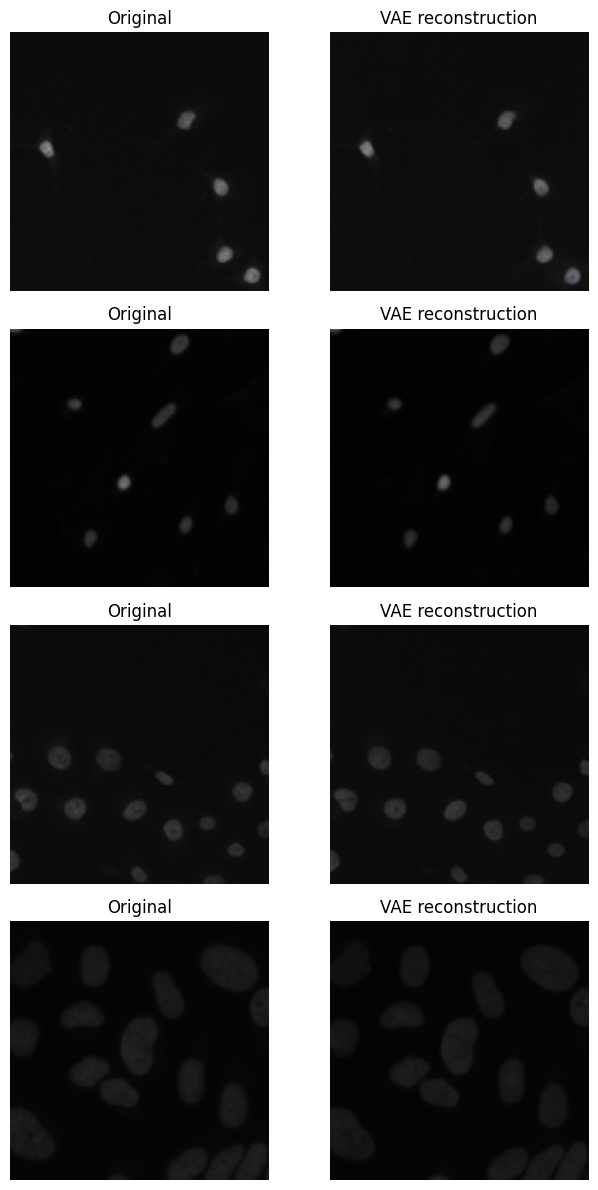

VAE reconstruction MAE: 0.008632095530629158


In [7]:
from diffusers import AutoencoderKL
from torchvision.utils import make_grid

VAE_ID='stabilityai/sd-vae-ft-mse'
LATENT_SCALE=0.18215
vae=AutoencoderKL.from_pretrained(VAE_ID).to(DEVICE).eval()
vae.requires_grad_(False)

@torch.no_grad()
def vae_reconstruct(batch):
    batch=batch.to(DEVICE)
    z=vae.encode(batch).latent_dist.mean*LATENT_SCALE
    return vae.decode(z/LATENT_SCALE).sample.clamp(-1,1)

x,_=next(iter(val_loader))
recon=vae_reconstruct(x)
fig,axs=plt.subplots(min(4,len(x)),2,figsize=(7,3*min(4,len(x))))
if len(x)==1: axs=np.array([axs])
for i in range(min(4,len(x))):
    axs[i,0].imshow(((x[i].permute(1,2,0).cpu().numpy()+1)/2).clip(0,1)); axs[i,0].set_title('Original'); axs[i,0].axis('off')
    axs[i,1].imshow(((recon[i].permute(1,2,0).cpu().numpy()+1)/2).clip(0,1)); axs[i,1].set_title('VAE reconstruction'); axs[i,1].axis('off')
plt.tight_layout(); plt.savefig(OUTPUT_ROOT/'vae_reconstruction_check.png',dpi=160); plt.show()
recon_mae=torch.mean(torch.abs(x.to(DEVICE)-recon)).item()
print("VAE reconstruction MAE:",recon_mae)


## 7. Encode latents and standardise using training statistics only

In [8]:
@torch.no_grad()
def encode_records(recs,batch_size=8):
    ds=MicroscopyDataset(recs)
    loader=DataLoader(ds,batch_size=batch_size,shuffle=False,num_workers=2)
    zs=[]; out_ids=[]
    for imgs,image_ids in loader:
        z=vae.encode(imgs.to(DEVICE)).latent_dist.mean*LATENT_SCALE
        zs.append(z.cpu().float())
        out_ids.extend(list(image_ids))
    return torch.cat(zs,dim=0),out_ids

z_train,train_latent_ids=encode_records(active_records)
z_val,val_latent_ids=encode_records(val_records)
z_test,test_latent_ids=encode_records(test_records)

latent_mean=z_train.mean(dim=(0,2,3),keepdim=True)
latent_std=z_train.std(dim=(0,2,3),keepdim=True).clamp(min=1e-6)
z_train=((z_train-latent_mean)/latent_std).half()
z_val=((z_val-latent_mean)/latent_std).half()
z_test=((z_test-latent_mean)/latent_std).half()

torch.save({'latent_mean':latent_mean,'latent_std':latent_std,'latent_scale':LATENT_SCALE,'vae_id':VAE_ID},
           OUTPUT_ROOT/'latent_normalisation_stats.pt')
torch.save({'z':z_train,'ids':train_latent_ids},CACHE_DIR/'train_latents.pt')
torch.save({'z':z_val,'ids':val_latent_ids},CACHE_DIR/'val_latents.pt')
torch.save({'z':z_test,'ids':test_latent_ids},CACHE_DIR/'test_latents.pt')
print("Latents:",z_train.shape,z_val.shape,z_test.shape)
print("Train latent mean/std:",z_train.float().mean().item(),z_train.float().std().item())


Latents: torch.Size([100, 4, 16, 16]) torch.Size([32, 4, 16, 16]) torch.Size([37, 4, 16, 16])
Train latent mean/std: -1.3554096085499623e-06 0.9999858736991882


## 8. Compact latent U-Net

In [9]:
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset,DataLoader
import copy

class SinusoidalTimeEmbedding(nn.Module):
    def __init__(self,dim):
        super().__init__(); self.dim=dim
    def forward(self,t):
        half=self.dim//2
        scale=math.log(10000)/max(half-1,1)
        emb=torch.exp(torch.arange(half,device=t.device)*-scale)
        emb=t.float()[:,None]*emb[None,:]
        return torch.cat([torch.sin(emb),torch.cos(emb)],dim=1)

class ResBlock(nn.Module):
    def __init__(self,in_ch,out_ch,time_dim):
        super().__init__()
        self.norm1=nn.GroupNorm(8,in_ch); self.conv1=nn.Conv2d(in_ch,out_ch,3,padding=1)
        self.time=nn.Sequential(nn.SiLU(),nn.Linear(time_dim,out_ch))
        self.norm2=nn.GroupNorm(8,out_ch); self.conv2=nn.Conv2d(out_ch,out_ch,3,padding=1)
        self.skip=nn.Conv2d(in_ch,out_ch,1) if in_ch!=out_ch else nn.Identity()
    def forward(self,x,t):
        h=self.conv1(F.silu(self.norm1(x)))
        h=h+self.time(t)[:,:,None,None]
        h=self.conv2(F.silu(self.norm2(h)))
        return h+self.skip(x)

class LatentUNet(nn.Module):
    def __init__(self,in_ch=4,base=64,time_dim=256):
        super().__init__()
        self.time_mlp=nn.Sequential(SinusoidalTimeEmbedding(time_dim),nn.Linear(time_dim,time_dim*4),
                                    nn.SiLU(),nn.Linear(time_dim*4,time_dim))
        self.in_conv=nn.Conv2d(in_ch,base,3,padding=1)
        self.down1=ResBlock(base,base,time_dim)
        self.downsample=nn.Conv2d(base,base*2,4,stride=2,padding=1)
        self.down2=ResBlock(base*2,base*2,time_dim)
        self.mid1=ResBlock(base*2,base*2,time_dim)
        self.mid2=ResBlock(base*2,base*2,time_dim)
        self.up=nn.ConvTranspose2d(base*2,base,4,stride=2,padding=1)
        self.up_block=ResBlock(base*2,base,time_dim)
        self.out_norm=nn.GroupNorm(8,base); self.out=nn.Conv2d(base,in_ch,3,padding=1)
    def forward(self,x,t):
        temb=self.time_mlp(t); h0=self.in_conv(x); h1=self.down1(h0,temb)
        h2=self.downsample(h1); h2=self.down2(h2,temb); h2=self.mid1(h2,temb); h2=self.mid2(h2,temb)
        h3=self.up(h2); h=self.up_block(torch.cat([h3,h1],dim=1),temb)
        return self.out(F.silu(self.out_norm(h)))

model=LatentUNet(in_ch=z_train.shape[1],base=64).to(DEVICE)
print("Parameters (M):",sum(p.numel() for p in model.parameters())/1e6)


Parameters (M): 2.004804


## 9. Cosine noise schedule, fixed validation and EMA training
Validation uses the same fixed noise and timesteps at every checkpoint. We save both the latest checkpoint and the best EMA checkpoint. Sampling will use the best validation checkpoint, not automatically the last step.

Terminal alpha_bar: 6.071716995847964e-08
step 50/5000 | train MSE=0.75199
step 100/5000 | train MSE=0.52990
step 150/5000 | train MSE=0.46942
step 200/5000 | train MSE=0.43718
step 250/5000 | train MSE=0.41680
FIXED EMA validation MSE=0.52998
NEW BEST EMA CHECKPOINT: /content/drive/MyDrive/BBBC038_LDM/ldm_outputs/final_homogeneous_cluster100/checkpoints/best_ema_checkpoint.pt
step 300/5000 | train MSE=0.43346
step 350/5000 | train MSE=0.41651
step 400/5000 | train MSE=0.40054
step 450/5000 | train MSE=0.40014
step 500/5000 | train MSE=0.38023
FIXED EMA validation MSE=0.41639
NEW BEST EMA CHECKPOINT: /content/drive/MyDrive/BBBC038_LDM/ldm_outputs/final_homogeneous_cluster100/checkpoints/best_ema_checkpoint.pt
step 550/5000 | train MSE=0.37325
step 600/5000 | train MSE=0.36256
step 650/5000 | train MSE=0.36225
step 700/5000 | train MSE=0.36924
step 750/5000 | train MSE=0.37233
FIXED EMA validation MSE=0.38857
NEW BEST EMA CHECKPOINT: /content/drive/MyDrive/BBBC038_LDM/ldm_outputs/final_

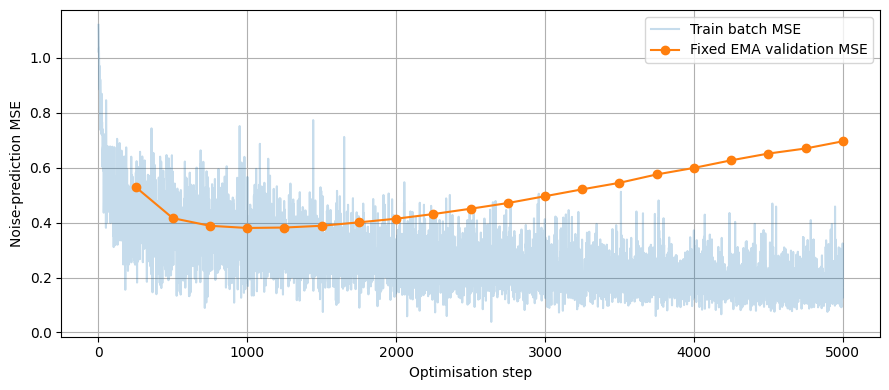

In [10]:
TIMESTEPS=200
s=0.008
tgrid=torch.arange(TIMESTEPS+1,device=DEVICE,dtype=torch.float64)
abar=torch.cos(((tgrid/TIMESTEPS)+s)/(1+s)*math.pi*0.5)**2
abar=abar/abar[0]
BETAS=(1-abar[1:]/abar[:-1]).clamp(1e-8,0.999).float()
ALPHAS=1-BETAS
ALPHAS_CUMPROD=torch.cumprod(ALPHAS,dim=0)
SQRT_ABAR=torch.sqrt(ALPHAS_CUMPROD)
SQRT_1M_ABAR=torch.sqrt(1-ALPHAS_CUMPROD)
print("Terminal alpha_bar:",ALPHAS_CUMPROD[-1].item())

def extract(a,t,shape):
    return a.gather(0,t).reshape(t.shape[0],*((1,)*(len(shape)-1)))

def q_sample(x0,t,noise):
    return extract(SQRT_ABAR,t,x0.shape)*x0+extract(SQRT_1M_ABAR,t,x0.shape)*noise

# Fixed validation corruption: same t and epsilon at every checkpoint.
val_z=z_val.float().to(DEVICE)
val_generator=torch.Generator(device=DEVICE).manual_seed(SEED+777)
val_t=torch.randint(0,TIMESTEPS,(len(val_z),),generator=val_generator,device=DEVICE)
val_noise=torch.randn(val_z.shape,generator=val_generator,device=DEVICE)
val_noisy=q_sample(val_z,val_t,val_noise)

@torch.no_grad()
def fixed_validation_loss(net,batch_size=8):
    net.eval(); losses=[]
    for start in range(0,len(val_z),batch_size):
        sl=slice(start,start+batch_size)
        pred=net(val_noisy[sl],val_t[sl])
        losses.append(F.mse_loss(pred.float(),val_noise[sl].float()).item())
    net.train()
    return float(np.mean(losses))

ema_model=copy.deepcopy(model).eval()
ema_model.requires_grad_(False)

@torch.no_grad()
def update_ema(ema,net,decay=0.995):
    for ep,p in zip(ema.parameters(),net.parameters()):
        ep.mul_(decay).add_(p.detach(),alpha=1-decay)

optimizer=torch.optim.AdamW(model.parameters(),lr=1e-4,weight_decay=1e-4)
scaler=torch.amp.GradScaler('cuda',enabled=True)
MAX_STEPS=5000
SAVE_EVERY=250
VALIDATE_EVERY=250
EMA_DECAY=0.995
train_loader_lat=DataLoader(torch.utils.data.TensorDataset(z_train.float()),batch_size=8,shuffle=True,drop_last=False)

latest_path=CHECKPOINT_DIR/'latest_checkpoint.pt'
best_path=CHECKPOINT_DIR/'best_ema_checkpoint.pt'
history=[]; val_history=[]; best_val=float('inf'); best_step=0; step=0
optimizer.zero_grad(set_to_none=True)
model.train(); start_time=time.time()

while step<MAX_STEPS:
    for (z0,) in train_loader_lat:
        z0=z0.to(DEVICE)
        t=torch.randint(0,TIMESTEPS,(z0.size(0),),device=DEVICE)
        noise=torch.randn_like(z0)
        noisy=q_sample(z0,t,noise)
        optimizer.zero_grad(set_to_none=True)
        with torch.autocast(device_type='cuda',dtype=torch.float16):
            pred=model(noisy,t)
            loss=F.mse_loss(pred.float(),noise.float())
        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(),1.0)
        scaler.step(optimizer); scaler.update()
        update_ema(ema_model,model,EMA_DECAY)
        step+=1; history.append(float(loss.detach().cpu()))

        if step%50==0:
            print(f"step {step}/{MAX_STEPS} | train MSE={np.mean(history[-50:]):.5f}")

        if step%VALIDATE_EVERY==0 or step==MAX_STEPS:
            v=fixed_validation_loss(ema_model)
            val_history.append({'step':step,'val_mse':v})
            print(f"FIXED EMA validation MSE={v:.5f}")
            if v<best_val:
                best_val=v; best_step=step
                torch.save({'step':step,'ema_model':ema_model.state_dict(),'val_mse':v,
                            'latent_mean':latent_mean.cpu(),'latent_std':latent_std.cpu(),
                            'train_ids':active_ids,'cluster':largest_cluster},best_path)
                print("NEW BEST EMA CHECKPOINT:",best_path)

        if step%SAVE_EVERY==0 or step==MAX_STEPS:
            torch.save({'step':step,'model':model.state_dict(),'ema_model':ema_model.state_dict(),
                        'optimizer':optimizer.state_dict(),'scaler':scaler.state_dict(),
                        'history':history,'val_history':val_history},latest_path)

        if step>=MAX_STEPS: break

elapsed=time.time()-start_time
print(f"Training time: {elapsed/60:.2f} min")
print("Best validation:",best_val,"at step",best_step)
pd.DataFrame({'step':np.arange(1,len(history)+1),'train_mse':history}).to_csv(OUTPUT_ROOT/'train_loss.csv',index=False)
pd.DataFrame(val_history).to_csv(OUTPUT_ROOT/'validation_loss_fixed.csv',index=False)

plt.figure(figsize=(9,4))
plt.plot(np.arange(1,len(history)+1),history,alpha=.25,label='Train batch MSE')
plt.plot([v['step'] for v in val_history],[v['val_mse'] for v in val_history],marker='o',label='Fixed EMA validation MSE')
plt.xlabel('Optimisation step'); plt.ylabel('Noise-prediction MSE'); plt.legend(); plt.grid(True)
plt.tight_layout(); plt.savefig(OUTPUT_ROOT/'training_validation_curve.png',dpi=160); plt.show()


## 10. Sample from the best EMA checkpoint

Sampling from best checkpoint at step 1000 with validation MSE 0.380682609975338


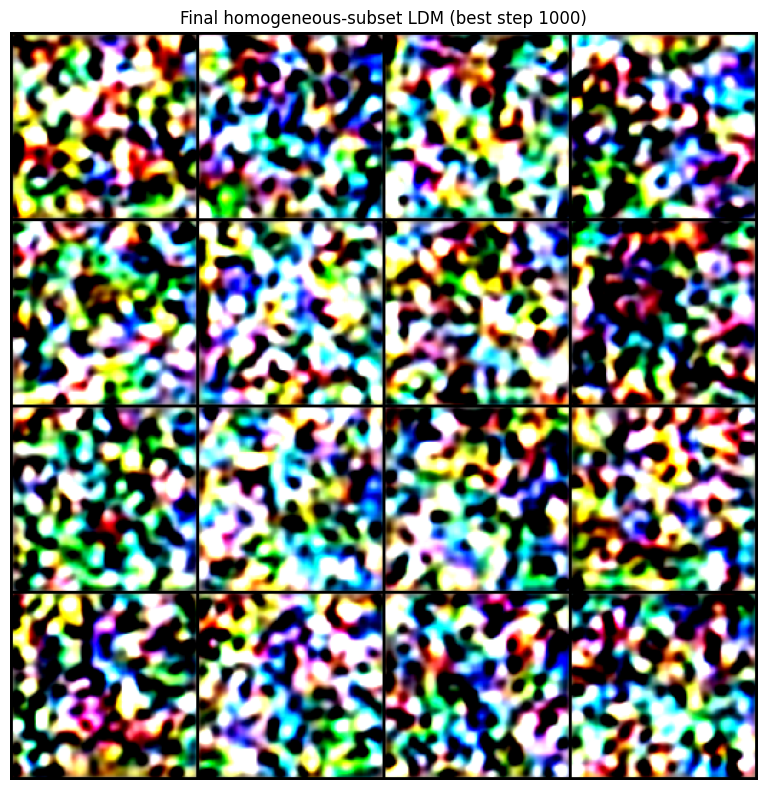

Samples: /content/drive/MyDrive/BBBC038_LDM/ldm_outputs/final_homogeneous_cluster100/generated_samples


In [11]:
best=torch.load(best_path,map_location='cpu')
ema_model.load_state_dict(best['ema_model'])
ema_model.eval()
print("Sampling from best checkpoint at step",best['step'],"with validation MSE",best['val_mse'])

@torch.no_grad()
def ddim_sample(net,n=100,sampling_steps=50):
    net.eval()
    x=torch.randn((n,z_train.shape[1],z_train.shape[-2],z_train.shape[-1]),device=DEVICE)
    times=torch.linspace(TIMESTEPS-1,0,sampling_steps,device=DEVICE).long()
    for i,ts in enumerate(times):
        t=torch.full((n,),int(ts.item()),device=DEVICE,dtype=torch.long)
        eps=net(x,t)
        a_t=ALPHAS_CUMPROD[ts]
        x0=(x-torch.sqrt(1-a_t)*eps)/torch.sqrt(a_t)
        if i==len(times)-1:
            x=x0
        else:
            tp=times[i+1]; a_prev=ALPHAS_CUMPROD[tp]
            x=torch.sqrt(a_prev)*x0+torch.sqrt(1-a_prev)*eps
    return x

@torch.no_grad()
def decode_latents(z_std):
    z_scaled=z_std*latent_std.to(DEVICE)+latent_mean.to(DEVICE)
    return vae.decode(z_scaled/LATENT_SCALE).sample.clamp(-1,1)

N_SAMPLES=100
sample_latents=ddim_sample(ema_model,n=N_SAMPLES,sampling_steps=50)
sample_images=decode_latents(sample_latents).cpu()
for i,im in enumerate(sample_images):
    arr=((im.permute(1,2,0).numpy()+1)*127.5).clip(0,255).astype('uint8')
    Image.fromarray(arr).save(SAMPLE_DIR/f'ldm_{i:04d}.png')

from torchvision.utils import make_grid
grid=make_grid((sample_images[:16]+1)/2,nrow=4)
plt.figure(figsize=(8,8)); plt.imshow(grid.permute(1,2,0)); plt.axis('off')
plt.title(f'Final homogeneous-subset LDM (best step {best_step})')
plt.tight_layout(); plt.savefig(OUTPUT_ROOT/'generated_montage.png',dpi=180); plt.show()
print("Samples:",SAMPLE_DIR)


## 11. Preliminary morphology diagnostics
The real comparison uses held-out images from the same appearance cluster. Real nuclei come from instance masks; generated foreground components come from Otsu thresholding. These are not equivalent segmentation procedures, so the distances below are exploratory diagnostics only. We omit circularity because the current contour estimator is unreliable for small raster masks.

In [12]:
def masks_for_id(image_id):
    return sorted((EXTRACT_DIR/str(image_id)/'masks').glob('*.png'))

def real_image_features(recs):
    rows=[]
    for r in recs:
        with Image.open(r['image_path']) as im: orig_size=im.size
        masks=masks_for_id(r['image_id'])
        union=np.zeros((IMAGE_SIZE,IMAGE_SIZE),dtype=bool)
        areas=[]
        for mp in masks:
            m=resize_pad_mask(mp,orig_size)
            union |= m
            if m.sum()>=5: areas.append(float(m.sum()))
        rows.append({'count':len(masks),'area':areas,'nuclear_area_fraction':float(union.mean())})
    return rows

def gen_image_features(images):
    rows=[]
    for im in images:
        gray=((im.mean(0).numpy()+1)/2).clip(0,1)
        u8=(gray*255).astype(np.uint8)
        _,bw=cv2.threshold(u8,0,1,cv2.THRESH_BINARY+cv2.THRESH_OTSU)
        if bw.mean()>0.5: bw=1-bw
        bw=cv2.morphologyEx(bw.astype(np.uint8),cv2.MORPH_OPEN,np.ones((3,3),np.uint8))
        n,lab,stats,_=cv2.connectedComponentsWithStats(bw,8)
        areas=[float(stats[j,cv2.CC_STAT_AREA]) for j in range(1,n) if stats[j,cv2.CC_STAT_AREA]>=5]
        rows.append({'count':len(areas),'area':areas,'nuclear_area_fraction':float(sum(areas)/(IMAGE_SIZE*IMAGE_SIZE))})
    return rows

def flatten(rows,key):
    out=[]
    for r in rows:
        v=r[key]; out.extend(v if isinstance(v,list) else [v])
    return np.asarray(out,dtype=float)

def hellinger_distance(x,y,bins=30):
    x=np.asarray(x,float); y=np.asarray(y,float)
    x=x[np.isfinite(x)]; y=y[np.isfinite(y)]
    if not len(x) or not len(y): return float('nan')
    lo=min(x.min(),y.min()); hi=max(x.max(),y.max())
    if hi<=lo: hi=lo+1e-8
    hx=np.histogram(x,bins=bins,range=(lo,hi))[0].astype(float)
    hy=np.histogram(y,bins=bins,range=(lo,hi))[0].astype(float)
    px=hx/(hx.sum()+1e-12); py=hy/(hy.sum()+1e-12)
    bc=np.sqrt(px*py).sum()
    return float(np.sqrt(max(0,1-bc)))

real_rows=real_image_features(test_records)
gen_rows=gen_image_features(sample_images)
distances={}
for key in ['area','count','nuclear_area_fraction']:
    distances[key]=hellinger_distance(flatten(real_rows,key),flatten(gen_rows,key))
print("Exploratory Hellinger distances:",distances)


Exploratory Hellinger distances: {'area': 0.2728634432887719, 'count': 0.533776277284265, 'nuclear_area_fraction': 0.9799543731831095}


## 12. Save all run outputs and metadata

In [13]:
metadata={
    'run_tag':RUN_TAG,'seed':SEED,'dataset_images':len(records),
    'train_pool_size':len(train_pool),'validation_pool_size':len(val_all),'test_pool_size':len(test_all),
    'largest_appearance_cluster':largest_cluster,'cluster_train_pool_size':len(cluster_train),
    'selected_train_count':len(active_records),'validation_same_cluster_count':len(val_records),
    'test_same_cluster_count':len(test_records),'selected_train_ids':active_ids,
    'vae_id':VAE_ID,'image_size':IMAGE_SIZE,'preprocessing':'aspect-preserving resize and median-corner padding',
    'latent_standardisation':'per-channel training-latent mean/std only',
    'timesteps':TIMESTEPS,'noise_schedule':'cosine','max_steps':MAX_STEPS,
    'best_step':best_step,'best_fixed_validation_mse':best_val,'reconstruction_mae':recon_mae,
    'exploratory_hellinger_distances':distances,
    'note':'Generated Otsu masks and real instance masks use different segmentation procedures; morphology distances are exploratory.'
}
with open(OUTPUT_ROOT/'run_metadata.json','w') as f: json.dump(metadata,f,indent=2)
pd.DataFrame([metadata]).drop(columns=['selected_train_ids']).to_csv(OUTPUT_ROOT/'run_summary.csv',index=False)
print(json.dumps({k:v for k,v in metadata.items() if k!='selected_train_ids'},indent=2))
print("\\nALL OUTPUTS:",OUTPUT_ROOT)


{
  "run_tag": "final_homogeneous_cluster100",
  "seed": 42,
  "dataset_images": 670,
  "train_pool_size": 536,
  "validation_pool_size": 67,
  "test_pool_size": 67,
  "largest_appearance_cluster": 0,
  "cluster_train_pool_size": 303,
  "selected_train_count": 100,
  "validation_same_cluster_count": 32,
  "test_same_cluster_count": 37,
  "vae_id": "stabilityai/sd-vae-ft-mse",
  "image_size": 128,
  "preprocessing": "aspect-preserving resize and median-corner padding",
  "latent_standardisation": "per-channel training-latent mean/std only",
  "timesteps": 200,
  "noise_schedule": "cosine",
  "max_steps": 5000,
  "best_step": 1000,
  "best_fixed_validation_mse": 0.380682609975338,
  "reconstruction_mae": 0.008632095530629158,
  "exploratory_hellinger_distances": {
    "area": 0.2728634432887719,
    "count": 0.533776277284265,
    "nuclear_area_fraction": 0.9799543731831095
  },
  "note": "Generated Otsu masks and real instance masks use different segmentation procedures; morphology dist

## 13. Output locations

All outputs are saved under:

`My Drive/BBBC038_LDM/ldm_outputs/final_homogeneous_cluster100/`

- `checkpoints/latest_checkpoint.pt`
- `checkpoints/best_ema_checkpoint.pt`
- `latent_cache/`
- `generated_samples/ldm_0000.png` … `ldm_0099.png`
- `generated_montage.png`
- `vae_reconstruction_check.png`
- `training_validation_curve.png`
- `train_loss.csv`
- `validation_loss_fixed.csv`
- `split_manifest.json`
- `latent_normalisation_stats.pt`
- `run_metadata.json`
- `run_summary.csv`

